# Can Budget, Release Date and Genre Predict Revenue?
The aim of this draft segment is to investigate whether a movie's budget, release date and genre can be used to predict its revenue. The Movie Database (TMDB) API was used to gather movie data, including titles, budgets, revenues, release dates, and genres, in order to investigate this question, the findings might shock you.

## Lets Build our Dataset
First we had to establish that we can connect to the TMDB API

In [2]:
from config import KEY,URL_START
import requests

url = f"{URL_START}/movie/popular"

header = {"Authorization": f"Bearer {KEY}","accept":"application/json"}

response = requests.get(url, headers=header)

if response.status_code == 200:
    print("connection made!")
else:
    print("connection failed :(")
    print(response.text)

connection made!


Next, we had to select the amount of entries we want, for this draft i went with 500.

In [3]:
from config import KEY,URL_START
import requests

url = f"{URL_START}/movie/popular"

header = {"Authorization": f"Bearer {KEY}","accept":"application/json"}

movieselection = []

for i in range(1,26):
    response = requests.get(url, headers=header, params={"page": i})
    if response.status_code == 200:
        data = response.json()
        movieselection.extend(data["results"])
    else:
        print("connection failed :(")
        print(response.text)

for entry in movieselection:
    print(entry)

{'adult': False, 'backdrop_path': '/9FE5eD92WfVCiivM9Pq9GVSrlWk.jpg', 'genre_ids': [28, 53, 80], 'id': 155, 'title': 'The Dark Knight', 'original_language': 'en', 'original_title': 'The Dark Knight', 'overview': 'Batman raises the stakes in his war on crime. With the help of Lt. Jim Gordon and District Attorney Harvey Dent, Batman sets out to dismantle the remaining criminal organizations that plague the streets. The partnership proves to be effective, but they soon find themselves prey to a reign of chaos unleashed by a rising criminal mastermind known to the terrified citizens of Gotham as the Joker.', 'popularity': 3247.0038, 'poster_path': '/qJ2tW6WMUDux911r6m7haRef0WH.jpg', 'release_date': '2008-07-16', 'softcore': False, 'video': False, 'vote_average': 8.539, 'vote_count': 37178}
{'adult': False, 'backdrop_path': '/sl5NJ1vtyhP9Vr88bB4blULsJYp.jpg', 'genre_ids': [16, 12, 14], 'id': 791523, 'title': 'Wildwood', 'original_language': 'en', 'original_title': 'Wildwood', 'overview': 'A

Now that we have all the data for the first 500 in the popular tab of TMDB API, we need to pick out what is relevant to us.
The relevant fields are: Title, Release Date, Genres, Budget and Revenue earned.

In [4]:
from config import KEY,URL_START # always hide API KEY
import requests

#set up
url = f"{URL_START}/movie/popular"
header = {"Authorization": f"Bearer {KEY}","accept":"application/json"}
movieselection = []

# obtain the default data for 500 movies
# (page 1-26 to do first 25 pages as TMDB stores entries in pages
# of 20 entries as 25x20=500)
for i in range(1,26):
    response = requests.get(url, headers=header, params={"page": i})
    if response.status_code == 200:
        data = response.json()
        movieselection.extend(data["results"])
    else:
        print("connection failed :(")
        print(response.text)

# refine our movie data
refinedmovieselection = []

for entry in movieselection:
    url = f"{URL_START}/movie/{entry['id']}"
    refineresponse = requests.get(url, headers=header)
    if refineresponse.status_code == 200:
        refineddata = refineresponse.json()
        #collect what we need to make our first questions prediction
        refinedmovieselection.append({
            "title": refineddata["title"],
            "release_date": refineddata["release_date"],
            "genres": ", ".join(genre["name"] for genre in refineddata["genres"]),
            "budget": refineddata["budget"],
            "revenue": refineddata["revenue"],
        })
    else:
        #incase we fail to pull a movie's data
        print("could not retrieve the data for:", entry["id"], entry["title"])

# print each movie data
for entry in refinedmovieselection:
    print(entry)

# helps view the total movie count retrieved
print("count:", len(refinedmovieselection))

{'title': 'The Dark Knight', 'release_date': '2008-07-16', 'genres': 'Action, Thriller, Crime', 'budget': 185000000, 'revenue': 1008480529}
{'title': 'Wildwood', 'release_date': '2026-10-19', 'genres': 'Animation, Adventure, Fantasy', 'budget': 100000000, 'revenue': 28871577}
{'title': 'Hope', 'release_date': '2026-07-15', 'genres': 'Science Fiction, Mystery, Action', 'budget': 46000000, 'revenue': 49456866}
{'title': 'Spider-Man: Brand New Day', 'release_date': '2026-07-29', 'genres': 'Science Fiction, Action, Adventure', 'budget': 225000000, 'revenue': 2519512338}
{'title': 'Drive - The Pretenders', 'release_date': '2026-10-27', 'genres': 'Romance, Thriller', 'budget': 0, 'revenue': 0}
{'title': 'Apocalypse Z: New World', 'release_date': '2026-10-09', 'genres': 'Action, Thriller, Horror', 'budget': 0, 'revenue': 0}
{'title': 'Fall 2: Deadpoint', 'release_date': '2026-09-01', 'genres': 'Thriller', 'budget': 3000000, 'revenue': 9256541}
{'title': 'The Awakening', 'release_date': '2026-

Next up, now that we have our dataset, we must store it in a csv file format for use down the line.

In [5]:
from config import KEY,URL_START # always hide API KEY
import requests
import csv

#set up
url = f"{URL_START}/movie/popular"
header = {"Authorization": f"Bearer {KEY}","accept":"application/json"}
movieselection = []

# obtain the default data for 500 movies
# (page 1-26 to do first 25 pages as TMDB stores entries in pages
# of 20 entries as 25x20=500)
for i in range(1,26):
    response = requests.get(url, headers=header, params={"page": i})
    if response.status_code == 200:
        data = response.json()
        movieselection.extend(data["results"])
    else:
        print("connection failed :(")
        print(response.text)

# refine our movie data
refinedmovieselection = []

for entry in movieselection:
    url = f"{URL_START}/movie/{entry['id']}"
    refineresponse = requests.get(url, headers=header)
    if refineresponse.status_code == 200:
        refineddata = refineresponse.json()
        #collect what we need to make our first questions prediction
        refinedmovieselection.append({
            "title": refineddata["title"],
            "release_date": refineddata["release_date"],
            "genres": ", ".join(genre["name"] for genre in refineddata["genres"]),
            "budget": refineddata["budget"],
            "revenue": refineddata["revenue"],
        })
    else:
        #incase we fail to pull a movie's data
        print("could not retrieve the data for:", entry["id"], entry["title"])

# print each movie data
for entry in refinedmovieselection:
    print(entry)
# helps view the total movie count retrieved
print("count:", len(refinedmovieselection))

# write to the csv file
with open("movies.csv", "w", newline="", encoding="utf-8") as file:
    file.write("title,release_date,genres,budget,revenue\n")
    for i in refinedmovieselection:
        file.write(f'{i["title"]},{i["release_date"]},{i["genres"]},{i["budget"]},{i["revenue"]}\n')


{'title': 'The Dark Knight', 'release_date': '2008-07-16', 'genres': 'Action, Thriller, Crime', 'budget': 185000000, 'revenue': 1008480529}
{'title': 'Wildwood', 'release_date': '2026-10-19', 'genres': 'Animation, Adventure, Fantasy', 'budget': 100000000, 'revenue': 28871577}
{'title': 'Hope', 'release_date': '2026-07-15', 'genres': 'Science Fiction, Mystery, Action', 'budget': 46000000, 'revenue': 49456866}
{'title': 'Spider-Man: Brand New Day', 'release_date': '2026-07-29', 'genres': 'Science Fiction, Action, Adventure', 'budget': 225000000, 'revenue': 2519512338}
{'title': 'Drive - The Pretenders', 'release_date': '2026-10-27', 'genres': 'Romance, Thriller', 'budget': 0, 'revenue': 0}
{'title': 'Apocalypse Z: New World', 'release_date': '2026-10-09', 'genres': 'Action, Thriller, Horror', 'budget': 0, 'revenue': 0}
{'title': 'Fall 2: Deadpoint', 'release_date': '2026-09-01', 'genres': 'Thriller', 'budget': 3000000, 'revenue': 9256541}
{'title': 'The Awakening', 'release_date': '2026-

But i felt as though organising the genres needed to be tidied up, so i ended off using \
DictWriter:https://dev.to/thumbone/dumping-data-with-pythons-csv-dictwriter-1g0

In [6]:
from config import KEY,URL_START # always hide API KEY
import requests
import csv

#set up
url = f"{URL_START}/movie/popular"
header = {"Authorization": f"Bearer {KEY}","accept":"application/json"}
movieselection = []

# obtain the default data for 500 movies
# (page 1-26 to do first 25 pages as TMDB stores entries in pages
# of 20 entries as 25x20=500)
for i in range(1,26):
    response = requests.get(url, headers=header, params={"page": i})
    if response.status_code == 200:
        data = response.json()
        movieselection.extend(data["results"])
    else:
        print("connection failed :(")
        print(response.text)

# refine our movie data
refinedmovieselection = []

for entry in movieselection:
    url = f"{URL_START}/movie/{entry['id']}"
    refineresponse = requests.get(url, headers=header)
    if refineresponse.status_code == 200:
        refineddata = refineresponse.json()
        #collect what we need to make our first questions prediction
        refinedmovieselection.append({
            "title": refineddata["title"],
            "release_date": refineddata["release_date"],
            "genres": ", ".join(genre["name"] for genre in refineddata["genres"]),
            "budget": refineddata["budget"],
            "revenue": refineddata["revenue"],
        })
    else:
        #incase we fail to pull a movie's data
        print("could not retrieve the data for:", entry["id"], entry["title"])

# print each movie data
for entry in refinedmovieselection:
    print(entry)
# helps view the total movie count retrieved
print("count:", len(refinedmovieselection))

# write to the csv file
with open("movies.csv", "w", newline="", encoding="utf-8") as file:
    fieldnames = ["title", "release_date", "genres", "budget", "revenue"]
    writer = csv.DictWriter(file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(refinedmovieselection)


{'title': 'The Dark Knight', 'release_date': '2008-07-16', 'genres': 'Action, Thriller, Crime', 'budget': 185000000, 'revenue': 1008480529}
{'title': 'Wildwood', 'release_date': '2026-10-19', 'genres': 'Animation, Adventure, Fantasy', 'budget': 100000000, 'revenue': 28871577}
{'title': 'Hope', 'release_date': '2026-07-15', 'genres': 'Science Fiction, Mystery, Action', 'budget': 46000000, 'revenue': 49456866}
{'title': 'Spider-Man: Brand New Day', 'release_date': '2026-07-29', 'genres': 'Science Fiction, Action, Adventure', 'budget': 225000000, 'revenue': 2519512338}
{'title': 'Drive - The Pretenders', 'release_date': '2026-10-27', 'genres': 'Romance, Thriller', 'budget': 0, 'revenue': 0}
{'title': 'Apocalypse Z: New World', 'release_date': '2026-10-09', 'genres': 'Action, Thriller, Horror', 'budget': 0, 'revenue': 0}
{'title': 'Fall 2: Deadpoint', 'release_date': '2026-09-01', 'genres': 'Thriller', 'budget': 3000000, 'revenue': 9256541}
{'title': 'The Awakening', 'release_date': '2026-

Now we move on to the data preprocessing section, using pandas we can import read and print out dataset we made.

In [7]:
import pandas as panda
movies = panda.read_csv("movies.csv")
print(movies)

                         title release_date  \
0              The Dark Knight   2008-07-16   
1                     Wildwood   2026-10-19   
2                         Hope   2026-07-15   
3    Spider-Man: Brand New Day   2026-07-29   
4       Drive - The Pretenders   2026-10-27   
..                         ...          ...   
495                  Elemental   2023-06-14   
496             Doctor Strange   2016-10-25   
497             One Night Only   2026-08-06   
498    Raiders of the Lost Ark   1981-06-12   
499             The Accountant   2016-10-13   

                                 genres     budget     revenue  
0               Action, Thriller, Crime  185000000  1008480529  
1         Animation, Adventure, Fantasy  100000000    28871577  
2      Science Fiction, Mystery, Action   46000000    49456866  
3    Science Fiction, Action, Adventure  225000000  2519512338  
4                     Romance, Thriller          0           0  
..                                  ...      

Now we get a brief rundown of the dataset we created using the TMDB API popular section

In [9]:
import pandas as panda
movies = panda.read_csv("movies.csv")
# analyse the data within the csv
print("\nSum of Missing Values")
print(movies.isnull().sum())
print("\nThe First 5 Movies")
print(movies.head())
print("\nMovies Information")
print(movies.info())
print("\nMovies Statistics")
print(movies.describe())


Sum of Missing Values
title           0
release_date    0
genres          0
budget          0
revenue         0
dtype: int64

The First 5 Movies
                       title release_date                              genres  \
0            The Dark Knight   2008-07-16             Action, Thriller, Crime   
1                   Wildwood   2026-10-19       Animation, Adventure, Fantasy   
2                       Hope   2026-07-15    Science Fiction, Mystery, Action   
3  Spider-Man: Brand New Day   2026-07-29  Science Fiction, Action, Adventure   
4     Drive - The Pretenders   2026-10-27                   Romance, Thriller   

      budget     revenue  
0  185000000  1008480529  
1  100000000    28871577  
2   46000000    49456866  
3  225000000  2519512338  
4          0           0  

Movies Information
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   title

Next we must clean our data, we will begin by removing any duplicate entries.

In [10]:
import pandas as panda
movies = panda.read_csv("movies.csv")
# analyse the data within the csv
print("\nSum of Missing Values")
print(movies.isnull().sum())
print("\nThe First 5 Movies")
print(movies.head())
print("\nMovies Information")
print(movies.info())
print("\nMovies Statistics")
print(movies.describe())

# clean up section
# checking for duplicate rows
print("\nDuplicate Movie Entries")
print(movies.duplicated().sum())

# then we remove duplicate movie rows
movies = movies.drop_duplicates()
# then check again to see if any were missed
print("\nDuplicate Movie Entries Check")
print(movies.duplicated().sum())
# save new cleaned data set
movies.to_csv("movies.csv", index=False)



Sum of Missing Values
title           0
release_date    0
genres          0
budget          0
revenue         0
dtype: int64

The First 5 Movies
                       title release_date                              genres  \
0            The Dark Knight   2008-07-16             Action, Thriller, Crime   
1                   Wildwood   2026-10-19       Animation, Adventure, Fantasy   
2                       Hope   2026-07-15    Science Fiction, Mystery, Action   
3  Spider-Man: Brand New Day   2026-07-29  Science Fiction, Action, Adventure   
4     Drive - The Pretenders   2026-10-27                   Romance, Thriller   

      budget     revenue  
0  185000000  1008480529  
1  100000000    28871577  
2   46000000    49456866  
3  225000000  2519512338  
4          0           0  

Movies Information
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   title

 Now we want to remove any entry with missing budget or revenue fields, we also will make sure that there is no placeholder fields by just disregarding anything under 10,000 dollars

In [11]:
import pandas as panda
movies = panda.read_csv("movies.csv")
# analyse the data within the csv
print("\nSum of Missing Values")
print(movies.isnull().sum())
print("\nThe First 5 Movies")
print(movies.head())
print("\nMovies Information")
print(movies.info())
print("\nMovies Statistics")
print(movies.describe())

# clean up section
# checking for duplicate rows
print("\nDuplicate Movie Entries")
print(movies.duplicated().sum())

# then we remove duplicate movie rows
movies = movies.drop_duplicates()
# then check again to see if any were missed
print("\nDuplicate Movie Entries Check")
print(movies.duplicated().sum())
# save new cleaned data set
movies.to_csv("movies.csv", index=False)

# now we want to remove any entries with missing revenue or budget fields
movies = movies.dropna(subset=["budget", "revenue"])
movies = movies[movies["revenue"]!=0]
movies = movies[movies["budget"]!=0]
print("\nMovies Count After Cleaning")
print(len(movies))
# save cleaned set
movies.to_csv("movies.csv", index=False)


Sum of Missing Values
title           0
release_date    0
genres          0
budget          0
revenue         0
dtype: int64

The First 5 Movies
                       title release_date                              genres  \
0            The Dark Knight   2008-07-16             Action, Thriller, Crime   
1                   Wildwood   2026-10-19       Animation, Adventure, Fantasy   
2                       Hope   2026-07-15    Science Fiction, Mystery, Action   
3  Spider-Man: Brand New Day   2026-07-29  Science Fiction, Action, Adventure   
4     Drive - The Pretenders   2026-10-27                   Romance, Thriller   

      budget     revenue  
0  185000000  1008480529  
1  100000000    28871577  
2   46000000    49456866  
3  225000000  2519512338  
4          0           0  

Movies Information
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   title

next we will extract the YEAR from their release date.

In [12]:
import pandas as panda
movies = panda.read_csv("movies.csv")
# analyse the data within the csv
print("\nSum of Missing Values")
print(movies.isnull().sum())
print("\nThe First 5 Movies")
print(movies.head())
print("\nMovies Information")
print(movies.info())
print("\nMovies Statistics")
print(movies.describe())

# clean up section
# checking for duplicate rows
print("\nDuplicate Movie Entries")
print(movies.duplicated().sum())

# then we remove duplicate movie rows
movies = movies.drop_duplicates()
# then check again to see if any were missed
print("\nDuplicate Movie Entries Check")
print(movies.duplicated().sum())
# save new cleaned data set
movies.to_csv("movies.csv", index=False)

# now we want to remove any entries with missing revenue or budget fields
movies = movies.dropna(subset=["budget", "revenue"])
movies = movies[movies["revenue"]!=0]
movies = movies[movies["budget"]!=0]
print("\nMovies Count After Cleaning")
print(len(movies))
# save cleaned set
movies.to_csv("movies.csv", index=False)

#extract fields we need, starting with turning date into just year
movies["release_date"] = panda.to_datetime(movies["release_date"])
movies["release_year"] = movies["release_date"].dt.year
# update the dataset with a new field
movies.to_csv("movies.csv", index=False)


Sum of Missing Values
title           0
release_date    0
genres          0
budget          0
revenue         0
dtype: int64

The First 5 Movies
                       title release_date                              genres  \
0            The Dark Knight   2008-07-16             Action, Thriller, Crime   
1                   Wildwood   2026-10-19       Animation, Adventure, Fantasy   
2                       Hope   2026-07-15    Science Fiction, Mystery, Action   
3  Spider-Man: Brand New Day   2026-07-29  Science Fiction, Action, Adventure   
4          Fall 2: Deadpoint   2026-09-01                            Thriller   

      budget     revenue  
0  185000000  1008480529  
1  100000000    28871577  
2   46000000    49456866  
3  225000000  2519512338  
4    3000000     9256541  

Movies Information
<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   title

Now we will put each movie into a T/F of if it fits into the genre, this is important for sorting them out later.

In [ ]:
import pandas as panda
movies = panda.read_csv("movies.csv")
# analyse the data within the csv
print("\nSum of Missing Values")
print(movies.isnull().sum())
print("\nThe First 5 Movies")
print(movies.head())
print("\nMovies Information")
print(movies.info())
print("\nMovies Statistics")
print(movies.describe())

# clean up section
# checking for duplicate rows
print("\nDuplicate Movie Entries")
print(movies.duplicated().sum())

# then we remove duplicate movie rows
movies = movies.drop_duplicates()
# then check again to see if any were missed
print("\nDuplicate Movie Entries Check")
print(movies.duplicated().sum())
# save new cleaned data set
movies.to_csv("movies.csv", index=False)

# now we want to remove any entries with missing revenue or budget fields
movies = movies.dropna(subset=["budget", "revenue"])
movies = movies[movies["revenue"]>10000]
movies = movies[movies["budget"]>10000]
print("\nMovies Count After Cleaning")
print(len(movies))
# save cleaned set
movies.to_csv("movies.csv", index=False)

#extract fields we need, starting with turning date into just year
movies["release_date"] = panda.to_datetime(movies["release_date"])
movies["release_year"] = movies["release_date"].dt.year
# update the dataset with a new field
movies.to_csv("movies.csv", index=False)

# convert movie genres into true or false fall in categories
genre_columns = movies["genres"].str.get_dummies(sep=", ")
# add new columns of T/F to our existing dataset
movies = panda.concat([movies, genre_columns], axis=1)
movies.to_csv("movies.csv", index=False) #save


Sum of Missing Values
title           0
release_date    0
genres          0
budget          0
revenue         0
release_year    0
dtype: int64

The First 5 Movies
                       title release_date                              genres  \
0            The Dark Knight   2008-07-16             Action, Thriller, Crime   
1                   Wildwood   2026-10-19       Animation, Adventure, Fantasy   
2                       Hope   2026-07-15    Science Fiction, Mystery, Action   
3  Spider-Man: Brand New Day   2026-07-29  Science Fiction, Action, Adventure   
4          Fall 2: Deadpoint   2026-09-01                            Thriller   

      budget     revenue  release_year  
0  185000000  1008480529          2008  
1  100000000    28871577          2026  
2   46000000    49456866          2026  
3  225000000  2519512338          2026  
4    3000000     9256541          2026  

Movies Information
<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 6 

Now we will make our graphing components.

In [15]:
import pandas as panda
movies = panda.read_csv("movies.csv")
movies = movies[["title", "release_date", "genres", "budget", "revenue"]]
print(movies.columns[movies.columns.duplicated()].tolist())
# analyse the data within the csv
print("\nSum of Missing Values")
print(movies.isnull().sum())
print("\nThe First 5 Movies")
print(movies.head())
print("\nMovies Information")
print(movies.info())
print("\nMovies Statistics")
print(movies.describe())

# clean up section
# checking for duplicate rows
print("\nDuplicate Movie Entries")
print(movies.duplicated().sum())

# then we remove duplicate movie rows
movies = movies.drop_duplicates()
# then check again to see if any were missed
print("\nDuplicate Movie Entries Check")
print(movies.duplicated().sum())
# save new cleaned data set
movies.to_csv("movies.csv", index=False)

# now we want to remove any entries with missing revenue or budget fields
movies = movies.dropna(subset=["budget", "revenue"])
movies = movies[movies["revenue"]!=0]
movies = movies[movies["budget"]!=0]
print("\nMovies Count After Cleaning")
print(len(movies))
# save cleaned set
movies.to_csv("movies.csv", index=False)

#extract fields we need, starting with turning date into just year
movies["release_date"] = panda.to_datetime(movies["release_date"])
movies["release_year"] = movies["release_date"].dt.year
# update the dataset with a new field
movies.to_csv("movies.csv", index=False)

# convert movie genres into true or false fall in categories
genre_columns = movies["genres"].str.get_dummies(sep=", ")
# add new columns of T/F to our existing dataset
movies = panda.concat([movies, genre_columns], axis=1)
movies.to_csv("movies.csv", index=False) #save

# titles for graph visualisation
movietitles = movies["title"]
# the features for our regression model
x_value = movies[["budget", "release_year"] + list(genre_columns.columns)]
# what I want to predict
y_value = movies["revenue"]

[]

Sum of Missing Values
title           0
release_date    0
genres          0
budget          0
revenue         0
dtype: int64

The First 5 Movies
                       title release_date                              genres  \
0            The Dark Knight   2008-07-16             Action, Thriller, Crime   
1                   Wildwood   2026-10-19       Animation, Adventure, Fantasy   
2                       Hope   2026-07-15    Science Fiction, Mystery, Action   
3  Spider-Man: Brand New Day   2026-07-29  Science Fiction, Action, Adventure   
4          Fall 2: Deadpoint   2026-09-01                            Thriller   

      budget     revenue  
0  185000000  1008480529  
1  100000000    28871577  
2   46000000    49456866  
3  225000000  2519512338  
4    3000000     9256541  

Movies Information
<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   ti

Now lets start exploring our data and graphing it.

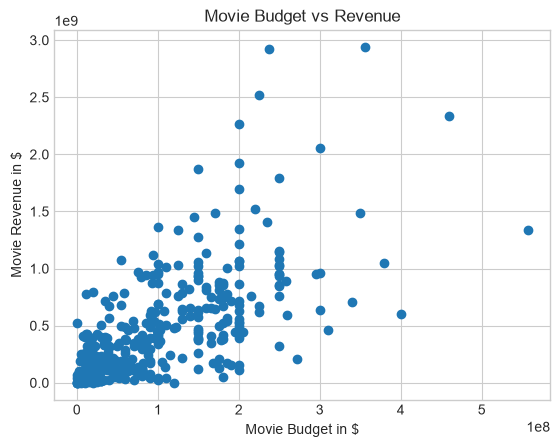

In [16]:
import pandas as panda
import matplotlib.pyplot as plot
movies = panda.read_csv("movies.csv")
plot.style.use('seaborn-v0_8-whitegrid')

plot.scatter(movies["budget"], movies["revenue"])

plot.xlabel("Movie Budget in $")
plot.ylabel("Movie Revenue in $")
plot.title("Movie Budget vs Revenue")
plot.show()

With how it is above it is not very clear what this all means, lets clear that up by adding some labels of the movies.

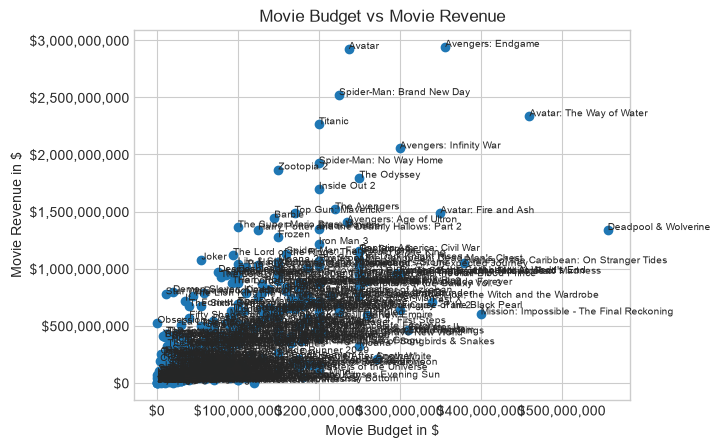

In [17]:
import pandas as panda
import matplotlib.pyplot as plot
from matplotlib.ticker import StrMethodFormatter
movies = panda.read_csv("movies.csv")
plot.style.use('seaborn-v0_8-whitegrid')

#create a chart
figuregraph, axes = plot.subplots()
#plot our points
axes.scatter(movies["budget"], movies["revenue"])
#for each movie, plot its title also
for i, movie in movies.iterrows():
    axes.annotate( movie["title"],(movie["budget"], movie["revenue"]),fontsize=7)

#format the labels so it shows in dollars and not in e
axes.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
axes.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))

#set axis labels & title
axes.set_xlabel("Movie Budget in $")
axes.set_ylabel("Movie Revenue in $")
axes.set_title("Movie Budget vs Movie Revenue")
plot.show()



Now lets identify revenue across the years as we can account and visualise for inflation and the growth of blockbuster movies across the years.

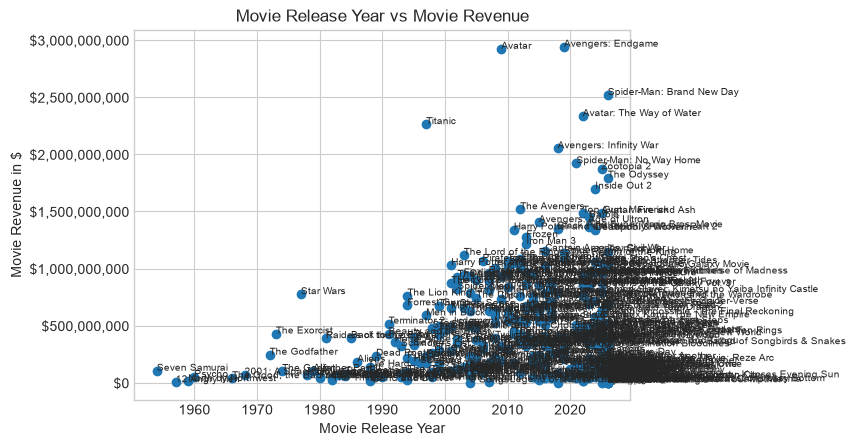

In [18]:
import pandas as panda
import matplotlib.pyplot as plot
from matplotlib.ticker import StrMethodFormatter
movies = panda.read_csv("movies.csv")
plot.style.use('seaborn-v0_8-whitegrid')

#create a chart
figuregraph, axes = plot.subplots()
#plot our points
axes.scatter(movies["release_year"], movies["revenue"])
#for each movie, plot its title also
for i, movie in movies.iterrows():
    axes.annotate( movie["title"],(movie["release_year"], movie["revenue"]),fontsize=7)

#format the label so it shows in dollars and not in e
axes.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))

#set axis labels & title
axes.set_xlabel("Movie Release Year")
axes.set_ylabel("Movie Revenue in $")
axes.set_title("Movie Release Year vs Movie Revenue")
plot.show()



Assessing the graphs we can take away a few key points.
In terms of Release Year vs Revenue, it clusters towards the right, this shows us that modern films seem to gross more at the box office., but then we must also factor in that ticket prices have gone up over time and franchises also play a huge factor, noticeable by the outliers of Avengers:Endgame, Spider-Man: Brand New Day and Avatar. Another key thing to note are the earlier year heavy hitters, such as The Godfather, Star Wars and Titanic. Although the record breakers are all modern films, the graph still shows that movies still make a modest amount at the box office and not all are huge heavy hitters, most films, even recent ones, sit well under $500M.

In the terms of Budget Vs Revenue, we can take away that budget doesn't always guarantee a huge return but have the possibility to and often mid-range budgets are the most reliable. We can see this in Deadpool & Wolverine and Mission impossible the Final Reckoning, the huge budget did not guarantee a huge return. However on the other-side some outliers can show a massive return on investment, Obsession is the most noteable.

So we can say that the relationship is positive, but is also loose. Big budget films have the potential of a higher return on investment ceiling, however it doesn't always work out and that the safest bet is to shoot in the middle.

Okay so now lets run the comparison between predicted and actual revenue, to test out our claims on our test and trained data.

Zootopia
Actual Revenue: 1025521689
Predicted Revenue: 624073316.707489

The Crow
Actual Revenue: 93722164
Predicted Revenue: 193652645.69129562

De Gaulle: Liberté
Actual Revenue: 13764497
Predicted Revenue: 200430923.9750196

Joker
Actual Revenue: 1078958629
Predicted Revenue: 302105098.2308116

Pirates of the Caribbean: At World's End
Actual Revenue: 961691209
Predicted Revenue: 1132444187.9864526

Dune: Part Two
Actual Revenue: 714844358
Predicted Revenue: 759638882.3818808

The Hangover Part III
Actual Revenue: 362000072
Predicted Revenue: 464783777.0400796

Brave
Actual Revenue: 538983207
Predicted Revenue: 742693186.6725804

Beetlejuice Beetlejuice
Actual Revenue: 452000435
Predicted Revenue: 451227220.472642

By Any Means
Actual Revenue: 16735918
Predicted Revenue: 217376619.68431842

Lee Cronin's The Mummy
Actual Revenue: 90552113
Predicted Revenue: 190263506.54944032

You Can See Everything
Actual Revenue: 63882597
Predicted Revenue: 139426419.4215438

Pinocchio: Unstrung
Act

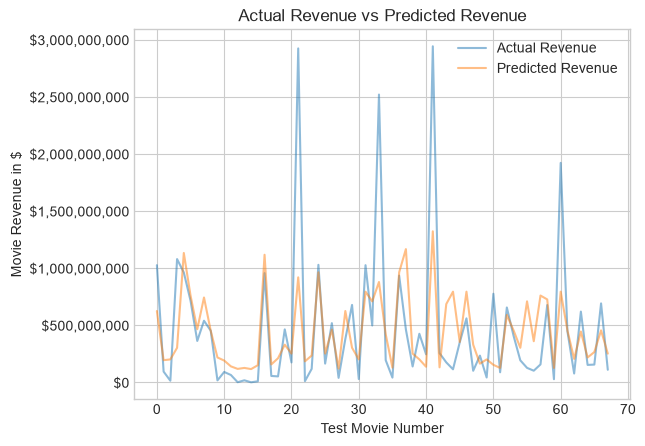

In [19]:
from datapreprocesser import x_value, y_value, movietitles
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from matplotlib.ticker import StrMethodFormatter
import pandas as panda
import matplotlib.pyplot as plot

trainingsetx,testingsetx,trainingsety,testingsety, trainingtitles, testingtitles = train_test_split(x_value, y_value, movietitles, test_size=0.2, random_state=42)
newmodel = LinearRegression()
newmodel.fit(trainingsetx, trainingsety)
predictions = newmodel.predict(testingsetx)

for i in range(len(testingtitles)):
    #get per test
    title = testingtitles.iloc[i]
    actualrev = testingsety.iloc[i]
    predictedrev = predictions[i]
    #print per movie
    print(title)
    print("Actual Revenue:", actualrev)
    print("Predicted Revenue:", predictedrev)
    print()

#time to test our validity with comparison of actual vs predicted
#create a table to store the revenue values
result = panda.DataFrame()
result["Actual Revenue"] = testingsety.values
result["Predicted Revenue"] = predictions

# Display a graph comparing both values
result.plot(alpha=0.5)
plot.gca().yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
plot.xlabel("Test Movie Number")
plot.ylabel("Movie Revenue in $")
plot.title("Actual Revenue vs Predicted Revenue")
plot.show()


As seen above, the graph is good at predicting the middle of the road, however it cannot properly predict the insane boom of franchises such as Marvel. Often these movies tend to break the norm due to many other factors due to a large prior fanbase, hype, cast and the long lineage of Marvel movies that lead up to the next.